In [1]:
#@title Run on TensorFlow 2.x
%tensorflow_version 2.x
from __future__ import absolute_import, division, print_function, unicode_literals

In [2]:
#@title Import relevant modules
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers
from matplotlib import pyplot as plt

# The following lines adjust the granularity of reporting. 
pd.options.display.max_rows = 10
pd.options.display.float_format = "{:.1f}".format

# The following line improves formatting when ouputting NumPy arrays.
np.set_printoptions(linewidth = 200)

In [3]:
(x_train, y_train),(x_test, y_test) = tf.keras.datasets.mnist.load_data()
# Output example #2917 of the training set.
x_train[2917]

11501568/11490434 [==============================] - 0s 0us/step


array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0, 127, 100, 156, 239, 224, 177, 213, 159,  70,  13,   0,   0

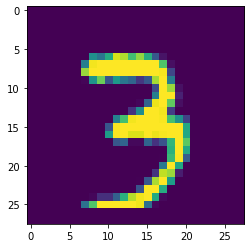

In [4]:
# Use false colors to visualize the array.
plt.imshow(x_train[2917])

## Task 1: Normalize feature values

Complete the following code cell to map each feature value from its current representation (an integer between 0 and 255) to a floating-point value between 0 and 1.0. Store the floating-point values in `x_train_normalized` and `x_test_normalized`.

In [5]:
#@title Double-click to see a solution to Task 1. 

x_train_normalized = x_train / 255.0
x_test_normalized = x_test / 255.0
print(x_train_normalized[2900][10])

[0.         0.         0.         0.         0.         0.         0.         0.55294118 1.         0.66666667 0.11372549 0.         0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.         0.         0.         0.         0.        ]


In [6]:
#@title Define the plotting function
def plot_curve(epochs, hist, list_of_metrics):
  """Plot a curve of one or more classification metrics vs. epoch."""  
  # list_of_metrics should be one of the names shown in:
  # https://www.tensorflow.org/tutorials/structured_data/imbalanced_data#define_the_model_and_metrics  

  plt.figure()
  plt.xlabel("Epoch")
  plt.ylabel("Value")

  for m in list_of_metrics:
    x = hist[m]
    plt.plot(epochs[1:], x[1:], label=m)

  plt.legend()

print("Loaded the plot_curve function.")

Loaded the plot_curve function.


In [7]:
def create_model(my_learning_rate):
  """Create and compile a deep neural net."""
  
  # All models in this course are sequential.
  model = tf.keras.models.Sequential()

  # The features are stored in a two-dimensional 28X28 array. 
  # Flatten that two-dimensional array into a a one-dimensional 
  # 784-element array.
  model.add(tf.keras.layers.Flatten(input_shape=(28, 28)))

  # Define the first hidden layer.   
  model.add(tf.keras.layers.Dense(units=32, activation='relu'))
  
  # Define a dropout regularization layer. 
  model.add(tf.keras.layers.Dropout(rate=0.2))

  # Define the output layer. The units parameter is set to 10 because
  # the model must choose among 10 possible output values (representing
  # the digits from 0 to 9, inclusive).
  #
  # Don't change this layer.
  model.add(tf.keras.layers.Dense(units=10, activation='softmax'))     
                           
  # Construct the layers into a model that TensorFlow can execute.  
  # Notice that the loss function for multi-class classification
  # is different than the loss function for binary classification.  
  model.compile(optimizer=tf.keras.optimizers.Adam(lr=my_learning_rate),
                loss="sparse_categorical_crossentropy",
                metrics=['accuracy'])
  
  return model    


def train_model(model, train_features, train_label, epochs,
                batch_size=None, validation_split=0.1):
  """Train the model by feeding it data."""

  history = model.fit(x=train_features, y=train_label, batch_size=batch_size,
                      epochs=epochs, shuffle=True, 
                      validation_split=validation_split)
 
  # To track the progression of training, gather a snapshot
  # of the model's metrics at each epoch. 
  epochs = history.epoch
  hist = pd.DataFrame(history.history)

  return epochs, hist    

Epoch 1/50
12/12 [==============================] - 1s 45ms/step - loss: 1.7532 - accuracy: 0.4077 - val_loss: 1.0275 - val_accuracy: 0.7778
Epoch 2/50
12/12 [==============================] - 0s 25ms/step - loss: 0.9113 - accuracy: 0.7355 - val_loss: 0.5367 - val_accuracy: 0.8652
Epoch 3/50
12/12 [==============================] - 0s 24ms/step - loss: 0.6304 - accuracy: 0.8103 - val_loss: 0.4182 - val_accuracy: 0.8852
Epoch 4/50
12/12 [==============================] - 0s 27ms/step - loss: 0.5255 - accuracy: 0.8423 - val_loss: 0.3634 - val_accuracy: 0.8997
Epoch 5/50
12/12 [==============================] - 0s 25ms/step - loss: 0.4656 - accuracy: 0.8605 - val_loss: 0.3263 - val_accuracy: 0.9093
Epoch 6/50
12/12 [==============================] - 0s 25ms/step - loss: 0.4252 - accuracy: 0.8723 - val_loss: 0.3019 - val_accuracy: 0.9188
Epoch 7/50
12/12 [==============================] - 0s 25ms/step - loss: 0.3988 - accuracy: 0.8808 - val_loss: 0.2856 - val_accuracy: 0.9222
Epoch 8/50
12

[0.14720751345157623, 0.9563000202178955]

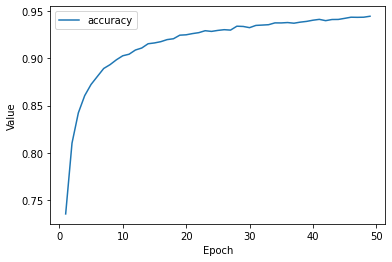

In [8]:
# The following variables are the hyperparameters.
learning_rate = 0.003
epochs = 50
batch_size = 4000
validation_split = 0.2

# Establish the model's topography.
my_model = create_model(learning_rate)

# Train the model on the normalized training set.
epochs, hist = train_model(my_model, x_train_normalized, y_train, 
                           epochs, batch_size, validation_split)

# Plot a graph of the metric vs. epochs.
list_of_metrics_to_plot = ['accuracy']
plot_curve(epochs, hist, list_of_metrics_to_plot)

# Evaluate against the test set.
print("\n Evaluate the new model against the test set:")
my_model.evaluate(x=x_test_normalized, y=y_test, batch_size=batch_size)

#ANSWER:
We build the model after making the desired normalizations.
When we look at the accuracy and loss values in the model, we see that there is an acceptable difference between the validation set and the training set. In addition, the accuracy value ​​is  high but loss values ​​can be made even better.

## Task 2: Optimize the model

Experiment with the following:

* number of hidden layers 
* number of nodes in each layer
* dropout regularization rate

What trends did you discover?  Can you reach at least 98% accuracy against the test set? 




In [9]:
#@title FIRSTLY I WILL TRY TO CHANGE NUMBER OFNODES IN HIDDEN LAYER
def try_nodes(x,my_learning_rate): #I defined a function that will build a model by changing the number of nodes in one hidden layer.
  """Create and compile a deep neural net."""
  
  # All models in this course are sequential.
  model = tf.keras.models.Sequential()

  # The features are stored in a two-dimensional 28X28 array. 
  # Flatten that two-dimensional array into a a one-dimensional 
  # 784-element array.
  model.add(tf.keras.layers.Flatten(input_shape=(28, 28)))

  # Define the first hidden layer.   
  model.add(tf.keras.layers.Dense(units=x, activation='relu'))
  
  # Define a dropout regularization layer. 
  model.add(tf.keras.layers.Dropout(rate=0.2))

  # Define the output layer. The units parameter is set to 10 because
  # the model must choose among 10 possible output values (representing
  # the digits from 0 to 9, inclusive).
  #
  # Don't change this layer.
  model.add(tf.keras.layers.Dense(units=10, activation='softmax'))     
                           
  # Construct the layers into a model that TensorFlow can execute.  
  # Notice that the loss function for multi-class classification
  # is different than the loss function for binary classification.  
  model.compile(optimizer=tf.keras.optimizers.Adam(lr=my_learning_rate),
                loss="sparse_categorical_crossentropy",
                metrics=['accuracy'])
  
  return model    


Epoch 1/50


12/12 [==============================] - 1s 41ms/step - loss: 1.6943 - accuracy: 0.4864 - val_loss: 0.8884 - val_accuracy: 0.7906
Epoch 2/50
12/12 [==============================] - 0s 28ms/step - loss: 0.8225 - accuracy: 0.7466 - val_loss: 0.4824 - val_accuracy: 0.8677
Epoch 3/50
12/12 [==============================] - 0s 29ms/step - loss: 0.5717 - accuracy: 0.8259 - val_loss: 0.3806 - val_accuracy: 0.8971
Epoch 4/50
12/12 [==============================] - 0s 29ms/step - loss: 0.4689 - accuracy: 0.8623 - val_loss: 0.3297 - val_accuracy: 0.9073
Epoch 5/50
12/12 [==============================] - 0s 27ms/step - loss: 0.4138 - accuracy: 0.8790 - val_loss: 0.2981 - val_accuracy: 0.9163
Epoch 6/50
12/12 [==============================] - 0s 28ms/step - loss: 0.3799 - accuracy: 0.8882 - val_loss: 0.2751 - val_accuracy: 0.9231
Epoch 7/50
12/12 [==============================] - 0s 29ms/step - loss: 0.3533 - accuracy: 0.8965 - val_loss: 0.2582 - val_accuracy: 0.9270
Epoch 8/50
12/12 [======

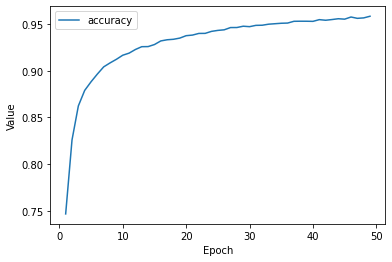

In [15]:
learning_rate = 0.003
epochs = 50
batch_size = 4000
validation_split = 0.2
nodes=40
# Establish the model's topography.
my_model = try_nodes(x=nodes,my_learning_rate=learning_rate)

# Train the model on the normalized training set.
epochs, hist = train_model(my_model, x_train_normalized, y_train, 
                           epochs, batch_size, validation_split)

# Plot a graph of the metric vs. epochs.
list_of_metrics_to_plot = ['accuracy']
plot_curve(epochs, hist, list_of_metrics_to_plot)

# Evaluate against the test set.
print("\n Evaluate the new model against the test set:")
my_model.evaluate(x=x_test_normalized, y=y_test, batch_size=batch_size)
plt.savefig("40 nodes for 1 layer")

In [16]:
#@title I WILL TRY TO CHANGE NUMBER OF NODES IN 2 LAYER
def try_nodes_with_2_layers(x,y,my_learning_rate): #I defined a function that will build a model by changing the number of nodes in two hidden layer.
  """Create and compile a deep neural net."""
  
  # All models in this course are sequential.
  model = tf.keras.models.Sequential()

  # The features are stored in a two-dimensional 28X28 array. 
  # Flatten that two-dimensional array into a a one-dimensional 
  # 784-element array.
  model.add(tf.keras.layers.Flatten(input_shape=(28, 28)))

  # Define the first hidden layer.   
  model.add(tf.keras.layers.Dense(units=x, activation='relu',name="hidden1"))

  # Define the second hidden layer.   
  model.add(tf.keras.layers.Dense(units=y, activation='relu', name="hidden2"))
  
  # Define a dropout regularization layer. 
  model.add(tf.keras.layers.Dropout(rate=0.2))

  # Define the output layer. The units parameter is set to 10 because
  # the model must choose among 10 possible output values (representing
  # the digits from 0 to 9, inclusive).
  #
  # Don't change this layer.
  model.add(tf.keras.layers.Dense(units=10, activation='softmax'))     
                           
  # Construct the layers into a model that TensorFlow can execute.  
  # Notice that the loss function for multi-class classification
  # is different than the loss function for binary classification.  
  model.compile(optimizer=tf.keras.optimizers.Adam(lr=my_learning_rate),
                loss="sparse_categorical_crossentropy",
                metrics=['accuracy'])
  
  return model    

Epoch 1/50


12/12 [==============================] - 1s 46ms/step - loss: 1.7982 - accuracy: 0.3946 - val_loss: 1.0864 - val_accuracy: 0.7642
Epoch 2/50
12/12 [==============================] - 0s 27ms/step - loss: 0.9803 - accuracy: 0.6931 - val_loss: 0.5310 - val_accuracy: 0.8560
Epoch 3/50
12/12 [==============================] - 0s 27ms/step - loss: 0.6478 - accuracy: 0.7986 - val_loss: 0.3898 - val_accuracy: 0.8934
Epoch 4/50
12/12 [==============================] - 0s 29ms/step - loss: 0.5046 - accuracy: 0.8469 - val_loss: 0.3276 - val_accuracy: 0.9054
Epoch 5/50
12/12 [==============================] - 0s 28ms/step - loss: 0.4406 - accuracy: 0.8675 - val_loss: 0.2960 - val_accuracy: 0.9143
Epoch 6/50
12/12 [==============================] - 0s 27ms/step - loss: 0.3948 - accuracy: 0.8834 - val_loss: 0.2698 - val_accuracy: 0.9208
Epoch 7/50
12/12 [==============================] - 0s 29ms/step - loss: 0.3611 - accuracy: 0.8950 - val_loss: 0.2522 - val_accuracy: 0.9276
Epoch 8/50
12/12 [======

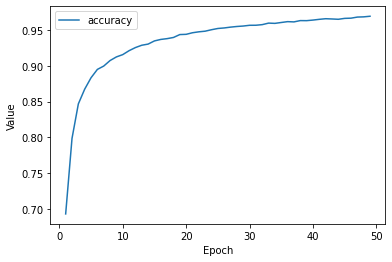

In [35]:
learning_rate = 0.003
epochs = 50
batch_size = 4000
validation_split = 0.2
nodes1=30
nodes2=30
# Establish the model's topography.
my_model = try_nodes_with_2_layers(x=nodes1,y=nodes2,my_learning_rate=learning_rate)

# Train the model on the normalized training set.
epochs, hist = train_model(my_model, x_train_normalized, y_train, 
                           epochs, batch_size, validation_split)

# Plot a graph of the metric vs. epochs.
list_of_metrics_to_plot = ['accuracy']
plot_curve(epochs, hist, list_of_metrics_to_plot)

# Evaluate against the test set.
print("\n Evaluate the new model against the test set:")
my_model.evaluate(x=x_test_normalized, y=y_test, batch_size=batch_size)
plt.savefig("30-30 nodes for 2 layer")

Before I come to the final task, I want to see the layer and node combinations that I have tried and saved before. In this way, I can do the last task using those combinations.

Text(0.5, 1.0, '40-25')

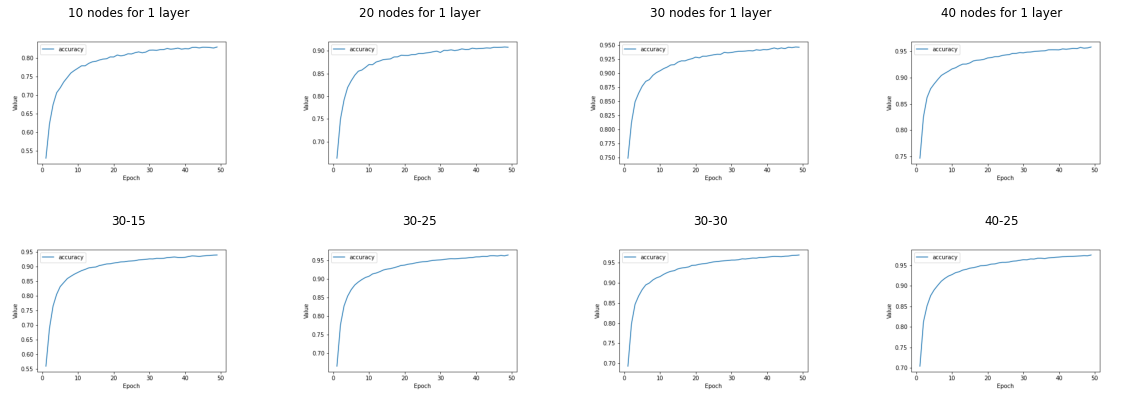

In [36]:
from PIL import Image
img1=Image.open("/content/10 nodes for 1 layer.png")
img2=Image.open("/content/20 nodes for 1 layer.png")
img3=Image.open("/content/30 nodes for 1 layer.png")
img4=Image.open("/content/40 nodes for 1 layer.png")
Img1=Image.open("/content/30-15 nodes for 2 layer.png")
Img2=Image.open("/content/30-25 nodes for 2 layer.png")
Img3=Image.open("/content/30-30 nodes for 2 layer.png")
Img4=Image.open("/content/40-25 nodes for 2 layer.png")
fig = plt.figure(figsize=(20, 7))
fig.add_subplot(2, 4, 1)
plt.imshow(img1)
plt.axis('off')
plt.title("10 nodes for 1 layer")
fig.add_subplot(2, 4, 2)
plt.imshow(img2)
plt.axis('off')
plt.title("20 nodes for 1 layer")
fig.add_subplot(2, 4, 3)
plt.imshow(img3)
plt.axis('off')
plt.title("30 nodes for 1 layer")
fig.add_subplot(2, 4, 4)
plt.imshow(img4)
plt.axis('off')
plt.title("40 nodes for 1 layer")
fig.add_subplot(2, 4, 5)
plt.imshow(Img1)
plt.axis('off')
plt.title("30-15")
fig.add_subplot(2, 4, 6)
plt.imshow(Img2)
plt.axis('off')
plt.title("30-25")
fig.add_subplot(2, 4, 7)
plt.imshow(Img3)
plt.axis('off')
plt.title("30-30")
fig.add_subplot(2, 4, 8)
plt.imshow(Img4)
plt.axis('off')
plt.title("40-25")

When we open and zoom this picture in a different tab, we see that the best combination is 40-25 or 40 combinations. We will apply these in the last task.

In [32]:
#@title I will try to change dropout regularization rate
def try_dropout_rate(x,my_learning_rate): #I defined a function that will build a model by changing the dropout regularization rate
  """Create and compile a deep neural net."""
  
  # All models in this course are sequential.
  model = tf.keras.models.Sequential()

  # The features are stored in a two-dimensional 28X28 array. 
  # Flatten that two-dimensional array into a a one-dimensional 
  # 784-element array.
  model.add(tf.keras.layers.Flatten(input_shape=(28, 28)))

  # Define the first hidden layer.   
  model.add(tf.keras.layers.Dense(units=40, activation='relu',name="hidden1"))

  # Define the second hidden layer.   
  model.add(tf.keras.layers.Dense(units=25, activation='relu', name="hidden2"))
  
  # Define a dropout regularization layer. 
  model.add(tf.keras.layers.Dropout(rate=x))

  # Define the output layer. The units parameter is set to 10 because
  # the model must choose among 10 possible output values (representing
  # the digits from 0 to 9, inclusive).
  #
  # Don't change this layer.
  model.add(tf.keras.layers.Dense(units=10, activation='softmax'))     
                           
  # Construct the layers into a model that TensorFlow can execute.  
  # Notice that the loss function for multi-class classification
  # is different than the loss function for binary classification.  
  model.compile(optimizer=tf.keras.optimizers.Adam(lr=my_learning_rate),
                loss="sparse_categorical_crossentropy",
                metrics=['accuracy'])
  
  return model    

Epoch 1/50
12/12 [==============================] - 1s 75ms/step - loss: 1.8849 - accuracy: 0.3512 - val_loss: 1.1495 - val_accuracy: 0.7753
Epoch 2/50
12/12 [==============================] - 0s 38ms/step - loss: 1.1087 - accuracy: 0.6419 - val_loss: 0.5782 - val_accuracy: 0.8659
Epoch 3/50
12/12 [==============================] - 0s 27ms/step - loss: 0.7444 - accuracy: 0.7712 - val_loss: 0.4160 - val_accuracy: 0.8923
Epoch 4/50
12/12 [==============================] - 0s 29ms/step - loss: 0.5899 - accuracy: 0.8234 - val_loss: 0.3423 - val_accuracy: 0.9087
Epoch 5/50
12/12 [==============================] - 0s 29ms/step - loss: 0.5034 - accuracy: 0.8509 - val_loss: 0.2963 - val_accuracy: 0.9181
Epoch 6/50
12/12 [==============================] - 0s 28ms/step - loss: 0.4512 - accuracy: 0.8699 - val_loss: 0.2666 - val_accuracy: 0.9247
Epoch 7/50
12/12 [==============================] - 0s 29ms/step - loss: 0.4106 - accuracy: 0.8805 - val_loss: 0.2450 - val_accuracy: 0.9315
Epoch 8/50
12

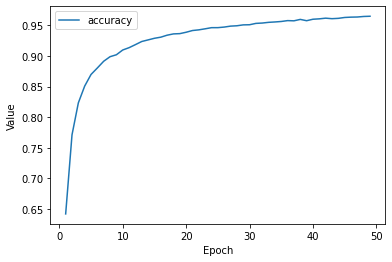

In [38]:
learning_rate = 0.003
epochs = 50
batch_size = 4000
validation_split = 0.2
dropoutRate=0.3
# Establish the model's topography.
my_model = try_dropout_rate(x=dropoutRate,my_learning_rate=learning_rate)

# Train the model on the normalized training set.
epochs, hist = train_model(my_model, x_train_normalized, y_train, 
                           epochs, batch_size, validation_split)

# Plot a graph of the metric vs. epochs.
list_of_metrics_to_plot = ['accuracy']
plot_curve(epochs, hist, list_of_metrics_to_plot)

# Evaluate against the test set.
print("\n Evaluate the new model against the test set:")
my_model.evaluate(x=x_test_normalized, y=y_test, batch_size=batch_size)
plt.savefig("0.3 Dropout rate", format="png")

Epoch 1/50
12/12 [==============================] - 1s 50ms/step - loss: 1.6783 - accuracy: 0.4836 - val_loss: 0.9212 - val_accuracy: 0.7862
Epoch 2/50
12/12 [==============================] - 0s 29ms/step - loss: 0.7803 - accuracy: 0.7631 - val_loss: 0.4575 - val_accuracy: 0.8733
Epoch 3/50
12/12 [==============================] - 0s 31ms/step - loss: 0.5135 - accuracy: 0.8434 - val_loss: 0.3425 - val_accuracy: 0.9016
Epoch 4/50
12/12 [==============================] - 0s 30ms/step - loss: 0.4112 - accuracy: 0.8759 - val_loss: 0.2955 - val_accuracy: 0.9148
Epoch 5/50
12/12 [==============================] - 0s 28ms/step - loss: 0.3616 - accuracy: 0.8934 - val_loss: 0.2666 - val_accuracy: 0.9230
Epoch 6/50
12/12 [==============================] - 0s 29ms/step - loss: 0.3276 - accuracy: 0.9031 - val_loss: 0.2484 - val_accuracy: 0.9275
Epoch 7/50
12/12 [==============================] - 0s 30ms/step - loss: 0.3015 - accuracy: 0.9107 - val_loss: 0.2316 - val_accuracy: 0.9344
Epoch 8/50
12

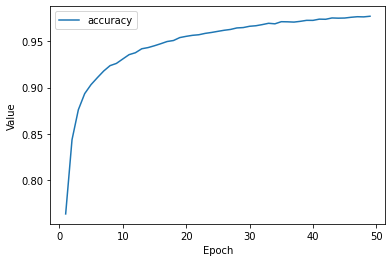

In [40]:
learning_rate = 0.003
epochs = 50
batch_size = 4000
validation_split = 0.2
dropoutRate=0.1
# Establish the model's topography.
my_model = try_dropout_rate(x=dropoutRate,my_learning_rate=learning_rate)

# Train the model on the normalized training set.
epochs, hist = train_model(my_model, x_train_normalized, y_train, 
                           epochs, batch_size, validation_split)

# Plot a graph of the metric vs. epochs.
list_of_metrics_to_plot = ['accuracy']
plot_curve(epochs, hist, list_of_metrics_to_plot)

# Evaluate against the test set.
print("\n Evaluate the new model against the test set:")
my_model.evaluate(x=x_test_normalized, y=y_test, batch_size=batch_size)
plt.savefig("0.1 Dropout rate", format="png")

In [41]:
#@title I will try to change dropout regularization rate
def try_dropout_rate_with_1layer(x,my_learning_rate): #I defined a function that will build a model by changing the dropout regularization rate
  """Create and compile a deep neural net."""
  
  # All models in this course are sequential.
  model = tf.keras.models.Sequential()

  # The features are stored in a two-dimensional 28X28 array. 
  # Flatten that two-dimensional array into a a one-dimensional 
  # 784-element array.
  model.add(tf.keras.layers.Flatten(input_shape=(28, 28)))

  # Define the first hidden layer.   
  model.add(tf.keras.layers.Dense(units=40, activation='relu',name="hidden1"))
  
  # Define a dropout regularization layer. 
  model.add(tf.keras.layers.Dropout(rate=x))

  # Define the output layer. The units parameter is set to 10 because
  # the model must choose among 10 possible output values (representing
  # the digits from 0 to 9, inclusive).
  #
  # Don't change this layer.
  model.add(tf.keras.layers.Dense(units=10, activation='softmax'))     
                           
  # Construct the layers into a model that TensorFlow can execute.  
  # Notice that the loss function for multi-class classification
  # is different than the loss function for binary classification.  
  model.compile(optimizer=tf.keras.optimizers.Adam(lr=my_learning_rate),
                loss="sparse_categorical_crossentropy",
                metrics=['accuracy'])
  
  return model    

Epoch 1/50
12/12 [==============================] - 1s 41ms/step - loss: 1.5690 - accuracy: 0.5038 - val_loss: 0.7926 - val_accuracy: 0.8131
Epoch 2/50
12/12 [==============================] - 0s 29ms/step - loss: 0.8150 - accuracy: 0.7539 - val_loss: 0.4778 - val_accuracy: 0.8749
Epoch 3/50
12/12 [==============================] - 0s 28ms/step - loss: 0.6047 - accuracy: 0.8204 - val_loss: 0.3856 - val_accuracy: 0.8971
Epoch 4/50
12/12 [==============================] - 0s 28ms/step - loss: 0.5132 - accuracy: 0.8493 - val_loss: 0.3364 - val_accuracy: 0.9070
Epoch 5/50
12/12 [==============================] - 0s 29ms/step - loss: 0.4605 - accuracy: 0.8639 - val_loss: 0.3086 - val_accuracy: 0.9141
Epoch 6/50
12/12 [==============================] - 0s 28ms/step - loss: 0.4271 - accuracy: 0.8744 - val_loss: 0.2876 - val_accuracy: 0.9219
Epoch 7/50
12/12 [==============================] - 0s 29ms/step - loss: 0.3997 - accuracy: 0.8849 - val_loss: 0.2709 - val_accuracy: 0.9254
Epoch 8/50
12

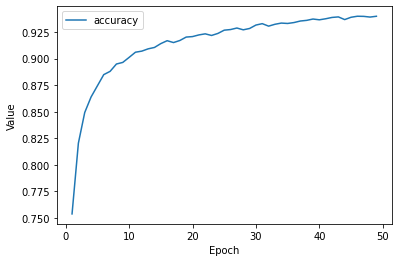

In [42]:
learning_rate = 0.003
epochs = 50
batch_size = 4000
validation_split = 0.2
dropoutRate=0.3
# Establish the model's topography.
my_model = try_dropout_rate_with_1layer(x=dropoutRate,my_learning_rate=learning_rate)

# Train the model on the normalized training set.
epochs, hist = train_model(my_model, x_train_normalized, y_train, 
                           epochs, batch_size, validation_split)

# Plot a graph of the metric vs. epochs.
list_of_metrics_to_plot = ['accuracy']
plot_curve(epochs, hist, list_of_metrics_to_plot)

# Evaluate against the test set.
print("\n Evaluate the new model against the test set:")
my_model.evaluate(x=x_test_normalized, y=y_test, batch_size=batch_size)
plt.savefig("0.3 Dropout rate for 1 layer", format="png")

Epoch 1/50
12/12 [==============================] - 1s 41ms/step - loss: 1.6109 - accuracy: 0.4851 - val_loss: 0.8954 - val_accuracy: 0.7868
Epoch 2/50
12/12 [==============================] - 0s 28ms/step - loss: 0.7527 - accuracy: 0.7875 - val_loss: 0.4809 - val_accuracy: 0.8717
Epoch 3/50
12/12 [==============================] - 0s 27ms/step - loss: 0.5171 - accuracy: 0.8493 - val_loss: 0.3705 - val_accuracy: 0.8965
Epoch 4/50
12/12 [==============================] - 0s 29ms/step - loss: 0.4246 - accuracy: 0.8732 - val_loss: 0.3213 - val_accuracy: 0.9104
Epoch 5/50
12/12 [==============================] - 0s 28ms/step - loss: 0.3736 - accuracy: 0.8903 - val_loss: 0.2914 - val_accuracy: 0.9195
Epoch 6/50
12/12 [==============================] - 0s 31ms/step - loss: 0.3382 - accuracy: 0.9014 - val_loss: 0.2695 - val_accuracy: 0.9243
Epoch 7/50
12/12 [==============================] - 0s 29ms/step - loss: 0.3138 - accuracy: 0.9084 - val_loss: 0.2520 - val_accuracy: 0.9274
Epoch 8/50
12

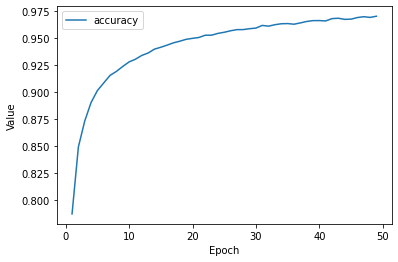

In [43]:
learning_rate = 0.003
epochs = 50
batch_size = 4000
validation_split = 0.2
dropoutRate=0.1
# Establish the model's topography.
my_model = try_dropout_rate_with_1layer(x=dropoutRate,my_learning_rate=learning_rate)

# Train the model on the normalized training set.
epochs, hist = train_model(my_model, x_train_normalized, y_train, 
                           epochs, batch_size, validation_split)

# Plot a graph of the metric vs. epochs.
list_of_metrics_to_plot = ['accuracy']
plot_curve(epochs, hist, list_of_metrics_to_plot)

# Evaluate against the test set.
print("\n Evaluate the new model against the test set:")
my_model.evaluate(x=x_test_normalized, y=y_test, batch_size=batch_size)
plt.savefig("0.1 Dropout rate for 1 layer", format="png")

Before trying the values that colab recommends to us here, I want to find the best one among my own.

Text(0.5, 1.0, '0.3 dropout rate for 2 layers 40-25')

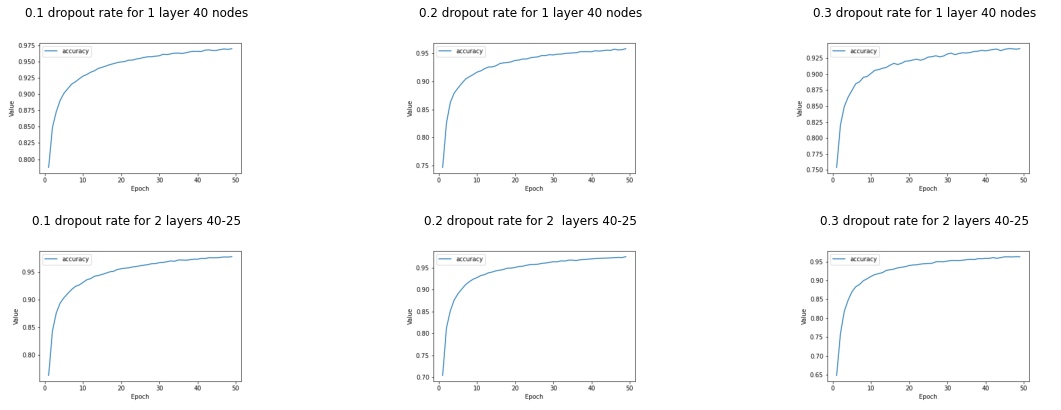

In [45]:
from PIL import Image
drop1=Image.open("/content/0.1 Dropout rate for 1 layer")
drop2=Image.open("/content/0.3 Dropout rate for 1 layer")
drop3=Image.open("/content/0.1 Dropout rate")
drop4=Image.open("/content/0.3 Dropout rate")
fig = plt.figure(figsize=(20, 7))
fig.add_subplot(2, 3, 1)
plt.imshow(drop1)
plt.axis('off')
plt.title("0.1 dropout rate for 1 layer 40 nodes")
fig.add_subplot(2, 3, 2)
plt.imshow(img4)
plt.axis('off')
plt.title("0.2 dropout rate for 1 layer 40 nodes")
fig.add_subplot(2, 3, 3)
plt.imshow(drop2)
plt.axis('off')
plt.title("0.3 dropout rate for 1 layer 40 nodes")
fig.add_subplot(2, 3, 4)
plt.imshow(drop3)
plt.axis('off')
plt.title("0.1 dropout rate for 2 layers 40-25")
fig.add_subplot(2, 3, 5)
plt.imshow(Img4)
plt.axis('off')
plt.title("0.2 dropout rate for 2  layers 40-25")
fig.add_subplot(2, 3, 6)
plt.imshow(drop4)
plt.axis('off')
plt.title("0.3 dropout rate for 2 layers 40-25")

Looking at the output, we see that the best combination among the ones I've tried is the combination with 2 layers 40-25 nodes and dropout rate of 0.2. It has an accuracy score of about 0.97, which is similar to the validation and test datasets.

now i will try with suggested values in colab

Epoch 1/50


12/12 [==============================] - 3s 163ms/step - loss: 0.9911 - accuracy: 0.7000 - val_loss: 0.3395 - val_accuracy: 0.9029
Epoch 2/50
12/12 [==============================] - 2s 143ms/step - loss: 0.3459 - accuracy: 0.8965 - val_loss: 0.2341 - val_accuracy: 0.9329
Epoch 3/50
12/12 [==============================] - 2s 128ms/step - loss: 0.2406 - accuracy: 0.9288 - val_loss: 0.1798 - val_accuracy: 0.9498
Epoch 4/50
12/12 [==============================] - 2s 152ms/step - loss: 0.1881 - accuracy: 0.9445 - val_loss: 0.1527 - val_accuracy: 0.9564
Epoch 5/50
12/12 [==============================] - 1s 95ms/step - loss: 0.1523 - accuracy: 0.9552 - val_loss: 0.1331 - val_accuracy: 0.9610
Epoch 6/50
12/12 [==============================] - 1s 94ms/step - loss: 0.1275 - accuracy: 0.9617 - val_loss: 0.1204 - val_accuracy: 0.9638
Epoch 7/50
12/12 [==============================] - 1s 94ms/step - loss: 0.1095 - accuracy: 0.9678 - val_loss: 0.1092 - val_accuracy: 0.9671
Epoch 8/50
12/12 [==

[0.08985721319913864, 0.9797999858856201]

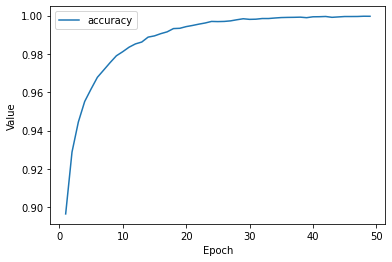

In [46]:
learning_rate = 0.003
epochs = 50
batch_size = 4000
validation_split = 0.2
nodes1=256
nodes2=128
# Establish the model's topography.
my_model = try_nodes_with_2_layers(x=nodes1,y=nodes2,my_learning_rate=learning_rate)

# Train the model on the normalized training set.
epochs, hist = train_model(my_model, x_train_normalized, y_train, 
                           epochs, batch_size, validation_split)

# Plot a graph of the metric vs. epochs.
list_of_metrics_to_plot = ['accuracy']
plot_curve(epochs, hist, list_of_metrics_to_plot)

# Evaluate against the test set.
print("\n Evaluate the new model against the test set:")
my_model.evaluate(x=x_test_normalized, y=y_test, batch_size=batch_size)

With these values, we reach a very high accuracy score of 0.99 for the training set. however, what we need to pay attention to here is that the more we increase the number of nodes, the higher the possibility of overfitting. In these values, there is a slight difference between the test, train and validation data sets, which tells us the signals that overfitting has started.